<a href="https://colab.research.google.com/github/attaramadhani/UAS-DL-Kelompok6-T3A-WBC-DomainShift/blob/main/notebooks/01_M2_Audit_EDA_Baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Milestone M2 - Audit Data Menyeluruh, EDA, Uji Kebocoran & Model Baseline (Topik T3-A)
**Kelompok 6 - Deep Learning A (Sistem Informasi, Universitas Trunojoyo Madura)**  
*Anggota:* Attala Alif Ramadhani Tri Hida (`230441100144`), Nafaul Hernanda Romadlona (`240441100125`), M. Rafly Kurniawan (`240441100086`), Naufal Husain (`240441100038`)

Notebook ini dijalankan bersih dari awal untuk:
1. Menghubungkan Google Colab ke folder Google Drive target (`101PbkgjCD-y_OaZPzRcqZzdgjoCf2ld8`).
2. Mengunduh dataset resmi Zheng et al. (2018) (Dataset 1 & Dataset 2) dan melakukan **audit data menyeluruh** (seluruh dimensi unik, masker mentah/stray pixel, sebaran luas & jumlah objek, rasio N:C, pemeriksaan kebocoran SHA-256 + dHash, dan tabel per citra 400 baris).
3. Menampilkan 5 grafik EDA termasuk verifikasi visual konversi masker pada **24 citra** (min. 20 citra sesuai Kisi-Kisi 3.1).
4. Melatih & mengevaluasi **1 model baseline** (`U-Net ResNet-34`, `D1 -> D2`), menyimpan kurva latih, bobot `.pth`, evaluasi per citra, dan menyinkronkan seluruh hasilnya langsung ke Google Drive.

In [1]:
import os
import sys
import subprocess
import pandas as pd

REPO_URL = "https://github.com/attaramadhani/UAS-DL-Kelompok6-T3A-WBC-DomainShift.git"
REPO_NAME = "UAS-DL-Kelompok6-T3A-WBC-DomainShift"
GDRIVE_FOLDER_ID = "101PbkgjCD-y_OaZPzRcqZzdgjoCf2ld8"
RUN_FROM_SCRATCH = True

if "google.colab" in sys.modules:
    if os.path.basename(os.getcwd()) != REPO_NAME:
        if not os.path.exists(REPO_NAME):
            subprocess.run(["git", "clone", REPO_URL], check=True)
        os.chdir(REPO_NAME)
    subprocess.run(["git", "pull", "--ff-only"], check=False)

if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.width", 2000)
pd.set_option("display.max_colwidth", 120)

import torch
from src.gdrive_sync import GDriveFolderSync

print(
    "PyTorch:",
    torch.__version__,
    "| CUDA:",
    torch.cuda.is_available(),
    torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
)

gdrive = GDriveFolderSync(folder_id=GDRIVE_FOLDER_ID, milestone_subdir="M2_Audit_EDA_Baseline")
gdrive.connect(require_in_colab=True)

PyTorch: 2.14.1+cu130 | CUDA: True Tesla T4


[OK] Terhubung ke Google Drive: 'UAS DL' (ID: 101PbkgjCD-y_OaZPzRcqZzdgjoCf2ld8) -> subfolder 'M2_Audit_EDA_Baseline' (ID: 1etdxu4Oslr1wXNCqxAdV1aO51QHxl5f_)


True

## 1. Unduh Dataset Resmi (Mendeley) & Tampilkan Keseluruhan Audit Dataset (`seed=42`)
Seluruh tabel di bawah menampilkan hasil audit lengkap tanpa pemotongan kolom/baris.

In [2]:
from IPython.display import display
from src.audit_eda import main as run_audit

audit_out = run_audit()
tables = audit_out["tables"]
df_audit = audit_out["per_image_df"]

print("=== 1. RINGKASAN EKSEKUTIF DOMAIN (D1 vs D2) ===")
display(tables["domain_overview"])

print("\n=== 2. KOMPOSISI SPLIT TETAP (seed=42, GROUP-AWARE) ===")
display(tables["split_composition"])

print("\n=== 3. LAPORAN PEMERIKSAAN KEBOCORAN DATA & DUPLIKAT (SHA-256 & dHash) ===")
display(tables["leakage_report"])

print("\n=== 4. SELURUH DIMENSI UNIK CITRA D1 & D2 (LENGKAP TANPA TERPOTONG) ===")
display(tables["dimensions_complete"])

print("\n=== 5. STATISTIK KELAS, JUMLAH KOMPONEN, LUAS OBJEK & RASIO N:C ===")
display(tables["object_statistics"])

print("\n=== 6. DAFTAR BERKAS MASKER DENGAN PIKSEL STRAY (<64) SEBELUM KONVERSI ===")
display(tables["stray_mask_files"])

print("\n=== 7. KESEIMBANGAN DISTRIBUSI ANTAR-SUBSET (TRAIN / VAL / TEST) ===")
split_balance = (
    df_audit.groupby(["domain", "split"], as_index=False)
    .agg(
        n_images=("id", "count"),
        bg_pct_mean=("bg_pct", "mean"),
        cyto_pct_mean=("cyto_pct", "mean"),
        nuc_pct_mean=("nuc_pct", "mean"),
        nc_ratio_mean=("nc_ratio", "mean"),
        fg_area_px_mean=("fg_area_px", "mean"),
    )
    .round(2)
)
display(split_balance)

print(f"\n=== 8. TABEL AUDIT LENGKAP PER CITRA ({len(df_audit)} CITRA D1 + D2) ===")
audit_view_cols = [
    "domain", "id", "split", "width", "height", "bg_pct", "cyto_pct", "nuc_pct",
    "nuc_area_px", "cyto_area_px", "nc_ratio", "nuc_components", "has_stray_pixels", "dhash", "sha256",
]
display(df_audit[audit_view_cols])

if gdrive.connected:
    n_up = gdrive.sync_paths([
        "logs/data_audit_report.json",
        "logs/data_audit_per_image.csv",
        "splits",
        "docs/figures",
    ])
    print(f"[GDrive] {n_up} berkas audit, split CSV, & grafik EDA M2 langsung tersimpan ke Google Drive.")

Audit lengkap selesai! Tersimpan di:
- /content/UAS-DL-Kelompok6-T3A-WBC-DomainShift/logs/data_audit_report.json
- /content/UAS-DL-Kelompok6-T3A-WBC-DomainShift/logs/data_audit_per_image.csv
=== 1. RINGKASAN EKSEKUTIF DOMAIN (D1 vs D2) ===


,Domain,Jumlah_Citra,Masker_Hilang,Citra_Rusak,Dimensi_Unik,Total_Size_MB,Nilai_Masker_Mentah,File_Stray_Pixel,"RGB_Mean_(R,G,B)","RGB_Std_(R,G,B)"
0,D1,300,0,0,30,12.01,"[0, 128, 255]",0,"[223.76, 198.81, 165.68]","[50.29, 75.29, 32.76]"
1,D2,100,0,0,1,25.75,"[0, 2, 3, 7, 9, 24, 25, 37, 42, 44, 45, 50, 128, 255]",5,"[210.52, 171.04, 174.68]","[45.22, 55.31, 23.19]"



=== 2. KOMPOSISI SPLIT TETAP (seed=42, GROUP-AWARE) ===


,Domain,Train,Val,Test,Total,Proporsi_(Train/Val/Test_%)
0,D1,210,45,45,300,70.0% / 15.0% / 15.0%
1,D2,70,15,15,100,70.0% / 15.0% / 15.0%



=== 3. LAPORAN PEMERIKSAAN KEBOCORAN DATA & DUPLIKAT (SHA-256 & dHash) ===


,Pemeriksaan,Hasil,Keterangan
0,Total Citra D1 + D2,400,Gabungan Dataset 1 + Dataset 2
1,Kebocoran Exact (SHA-256) Lintas Split,0,[]
2,Kebocoran Near-Duplicate (dHash <= 4 bit) Lintas Split,0,[]
3,Near-Duplicate Lintas Domain (dHash <= 4 bit),0,[]
4,Grup Duplikat Identik Dikunci di Set Train,1,"[('D1/112(train)', 'D1/139(train)')]"


... (7 outputs left out)

,domain,split,n_images,bg_pct_mean,cyto_pct_mean,nuc_pct_mean,nc_ratio_mean,fg_area_px_mean
0,D1,test,45,69.35,18.19,12.46,0.87,4292.71
1,D1,train,210,68.51,19.04,12.44,0.80,4394.74
2,D1,val,45,69.11,18.32,12.57,0.80,4255.53
3,D2,test,15,78.92,11.32,9.76,1.61,18971.00
4,D2,train,70,77.53,12.52,9.95,0.98,20219.39
5,D2,val,15,74.21,14.60,11.19,0.93,23207.40



=== 8. TABEL AUDIT LENGKAP PER CITRA (400 CITRA D1 + D2) ===


,domain,id,split,width,height,bg_pct,cyto_pct,nuc_pct,nuc_area_px,cyto_area_px,nc_ratio,nuc_components,has_stray_pixels,dhash,sha256
0,D1,001,train,120,120,84.06,4.79,11.15,1606,690,2.3275,1,False,46b24c869e4fb003,f35ef4e068ec811a
1,D1,002,test,120,120,58.22,28.95,12.83,1847,4169,0.4430,2,False,f11c0e061f4e0cda,2be35d66430b0d84
2,D1,003,train,120,120,58.36,29.78,11.86,1708,4288,0.3983,1,False,1e1f33330f0e14da,fb8646fc6c4365e2
3,D1,004,train,120,120,65.95,21.41,12.64,1820,3083,0.5903,1,False,3a4e1e17071f968c,3cffa7a0f2136095
4,D1,005,train,120,120,60.03,28.94,11.03,1588,4168,0.3810,1,False,98284c4c4e0f0dc1,e7a38547f1695aa4
5,D1,006,train,120,120,63.83,22.65,13.53,1948,3261,0.5974,2,False,ae0e373737974ee1,be3caa6e48d844ae
6,D1,007,test,120,120,75.08,11.29,13.63,1962,1626,1.2066,1,False,45480f06060e98ba,a17aced5e0bed16a
7,D1,008,train,120,120,63.92,22.30,13.78,1985,3211,0.6182,2,False,a48c1f17330f8ef0,6e2fbe72e03e6217
8,D1,009,train,120,120,54.74,31.74,13.53,1948,4570,0.4263,1,False,8e930f3323078e28,e6d24f454c7e6c81
9,D1,010,train,120,120,50.12,33.19,16.69,2404,4779,0.5030,1,False,c70f0f271f178f46,b2b3383de37f4509


[GDrive] 9 berkas audit, split CSV, & grafik EDA M2 langsung tersimpan ke Google Drive.


## 2. Grafik EDA, Verifikasi Visual Konversi 24 Citra & Preview Macenko / Reinhard

=== fig1_sample_overlay_d1_d2.png ===


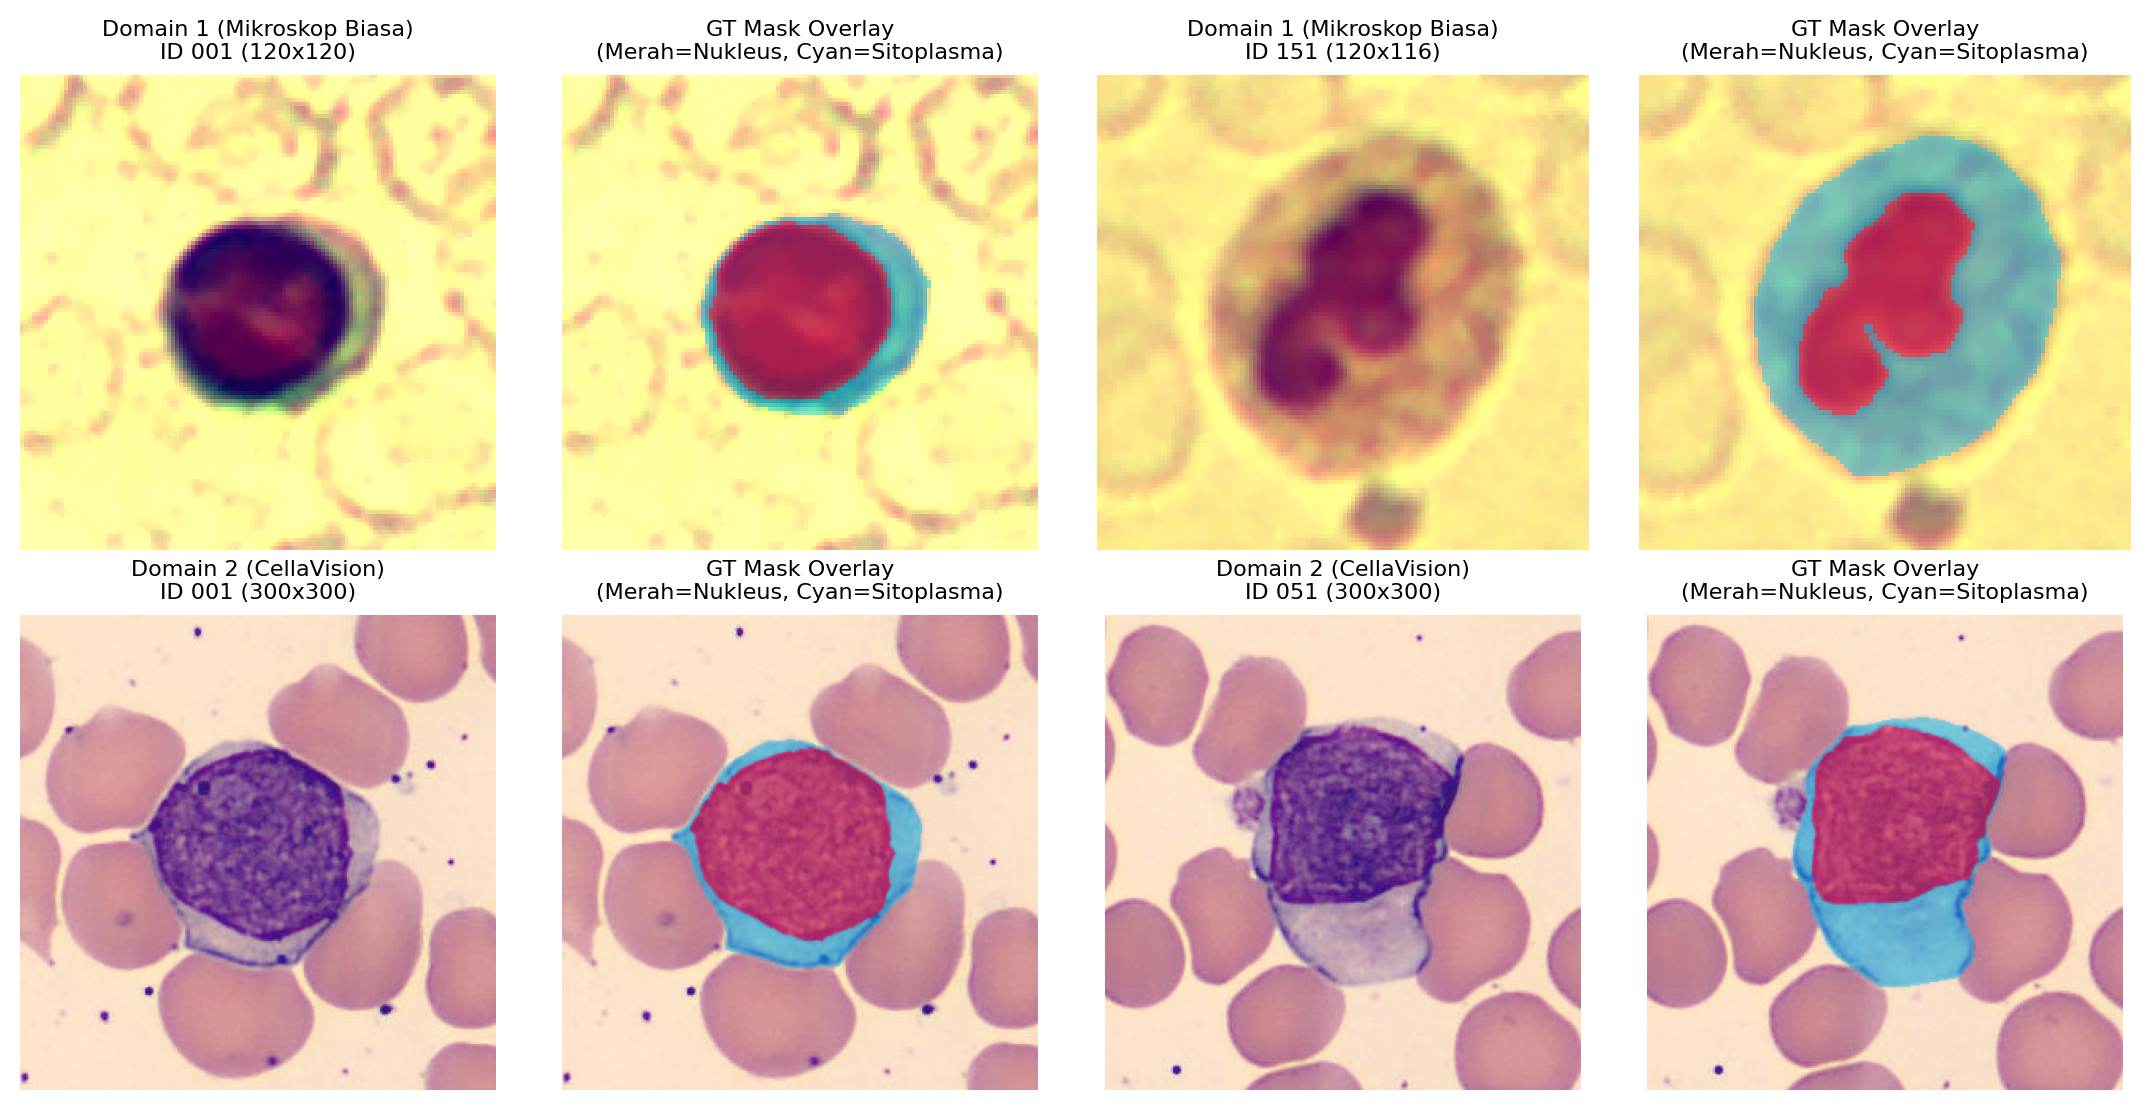

=== fig1b_mask_conversion_audit_24.png ===


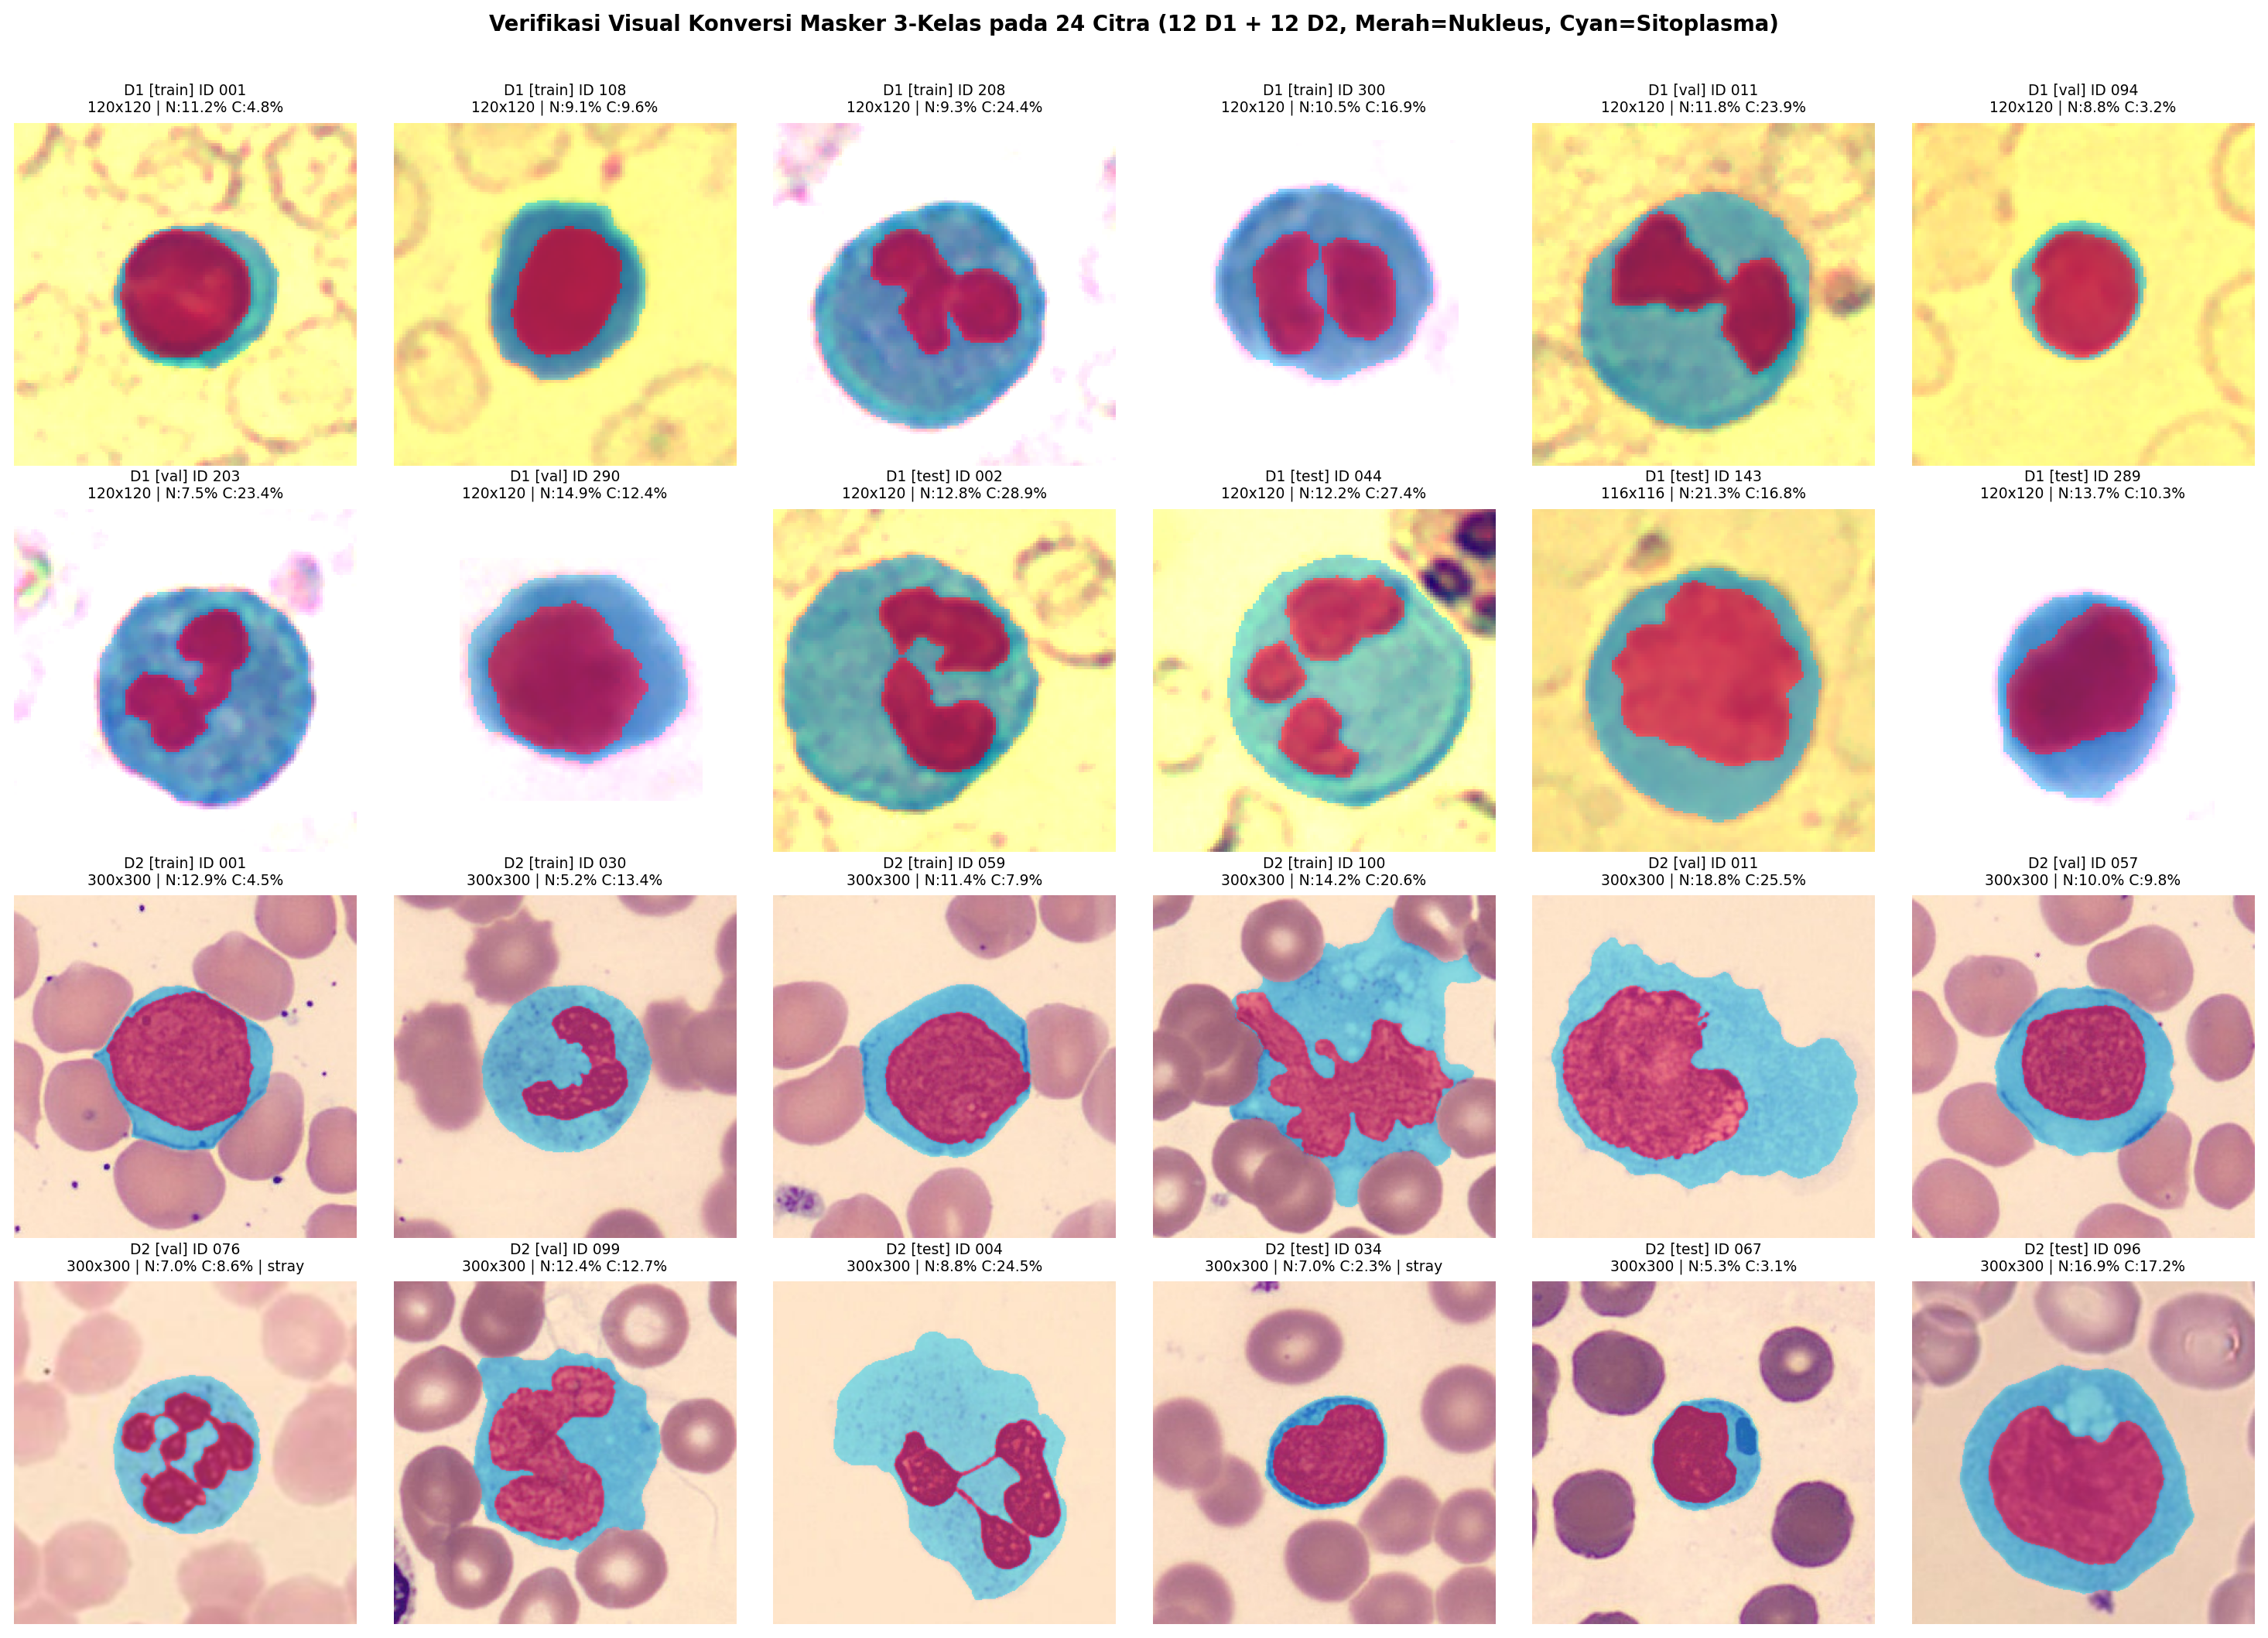

=== fig2_eda_distributions.png ===


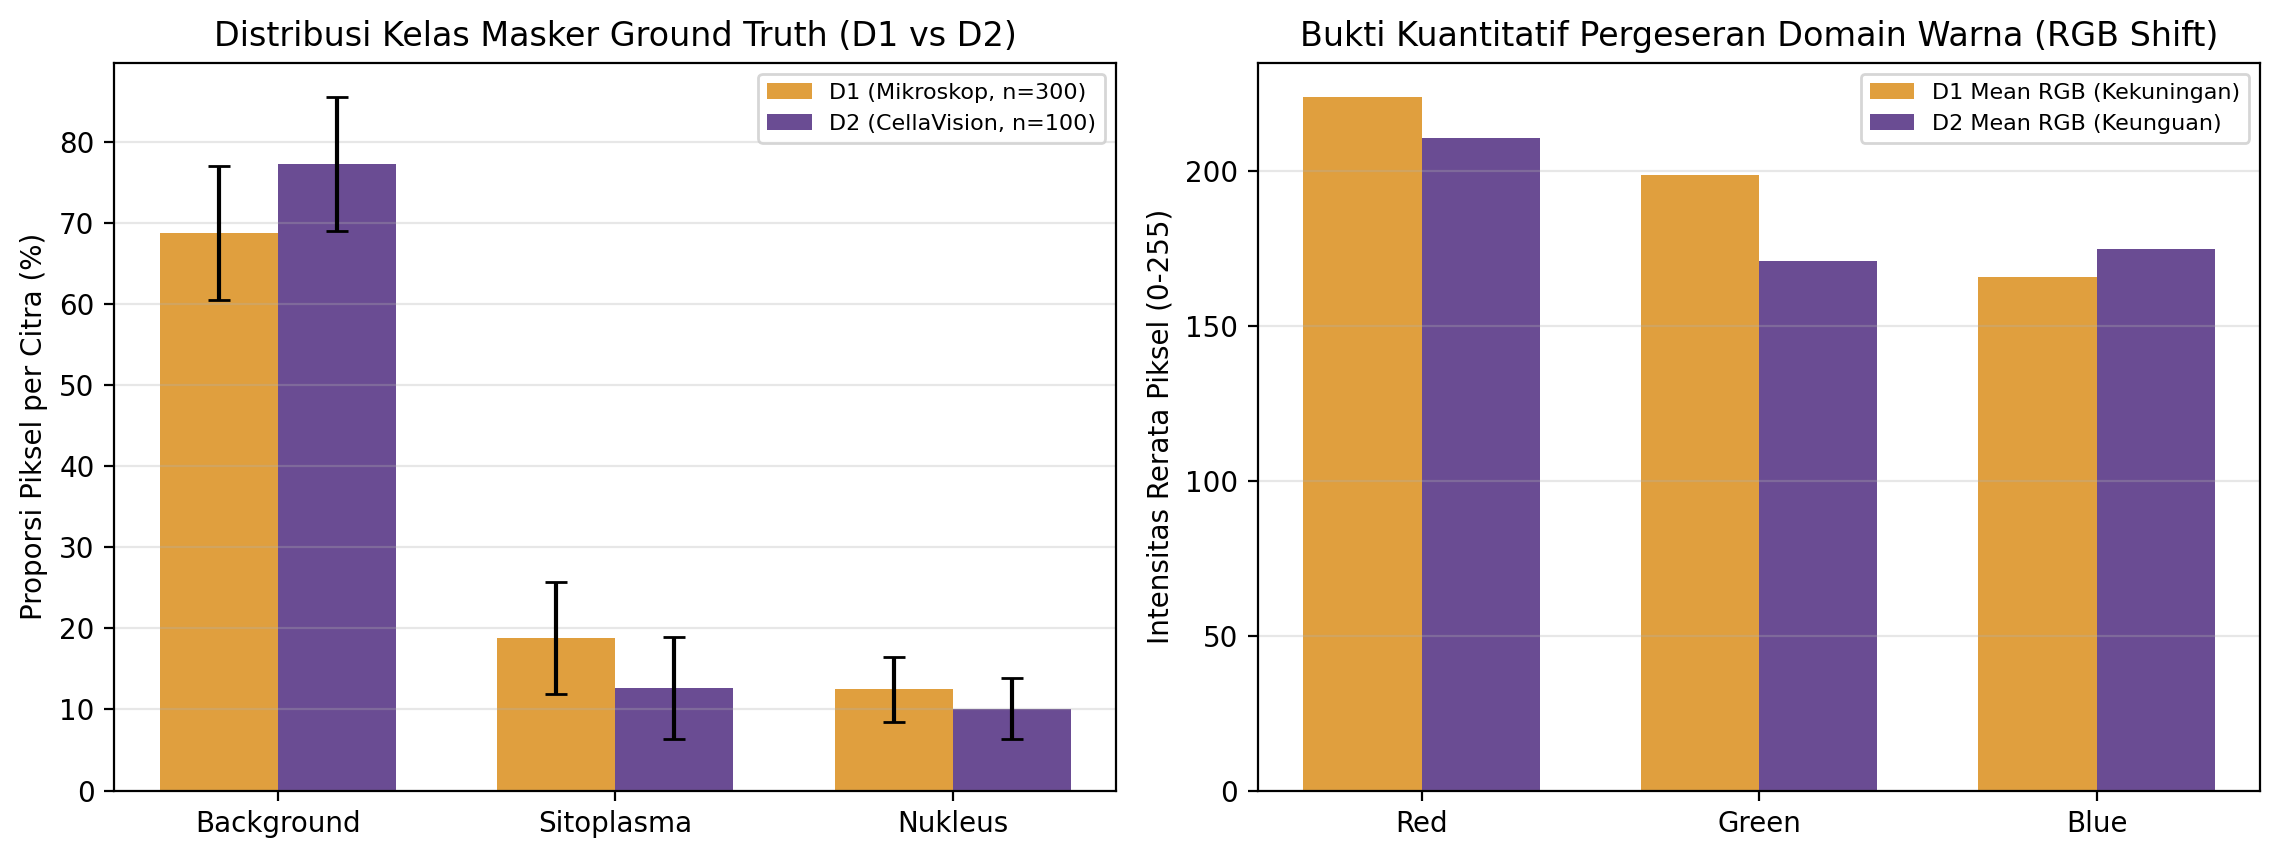

=== fig2b_object_size_and_nc_distributions.png ===


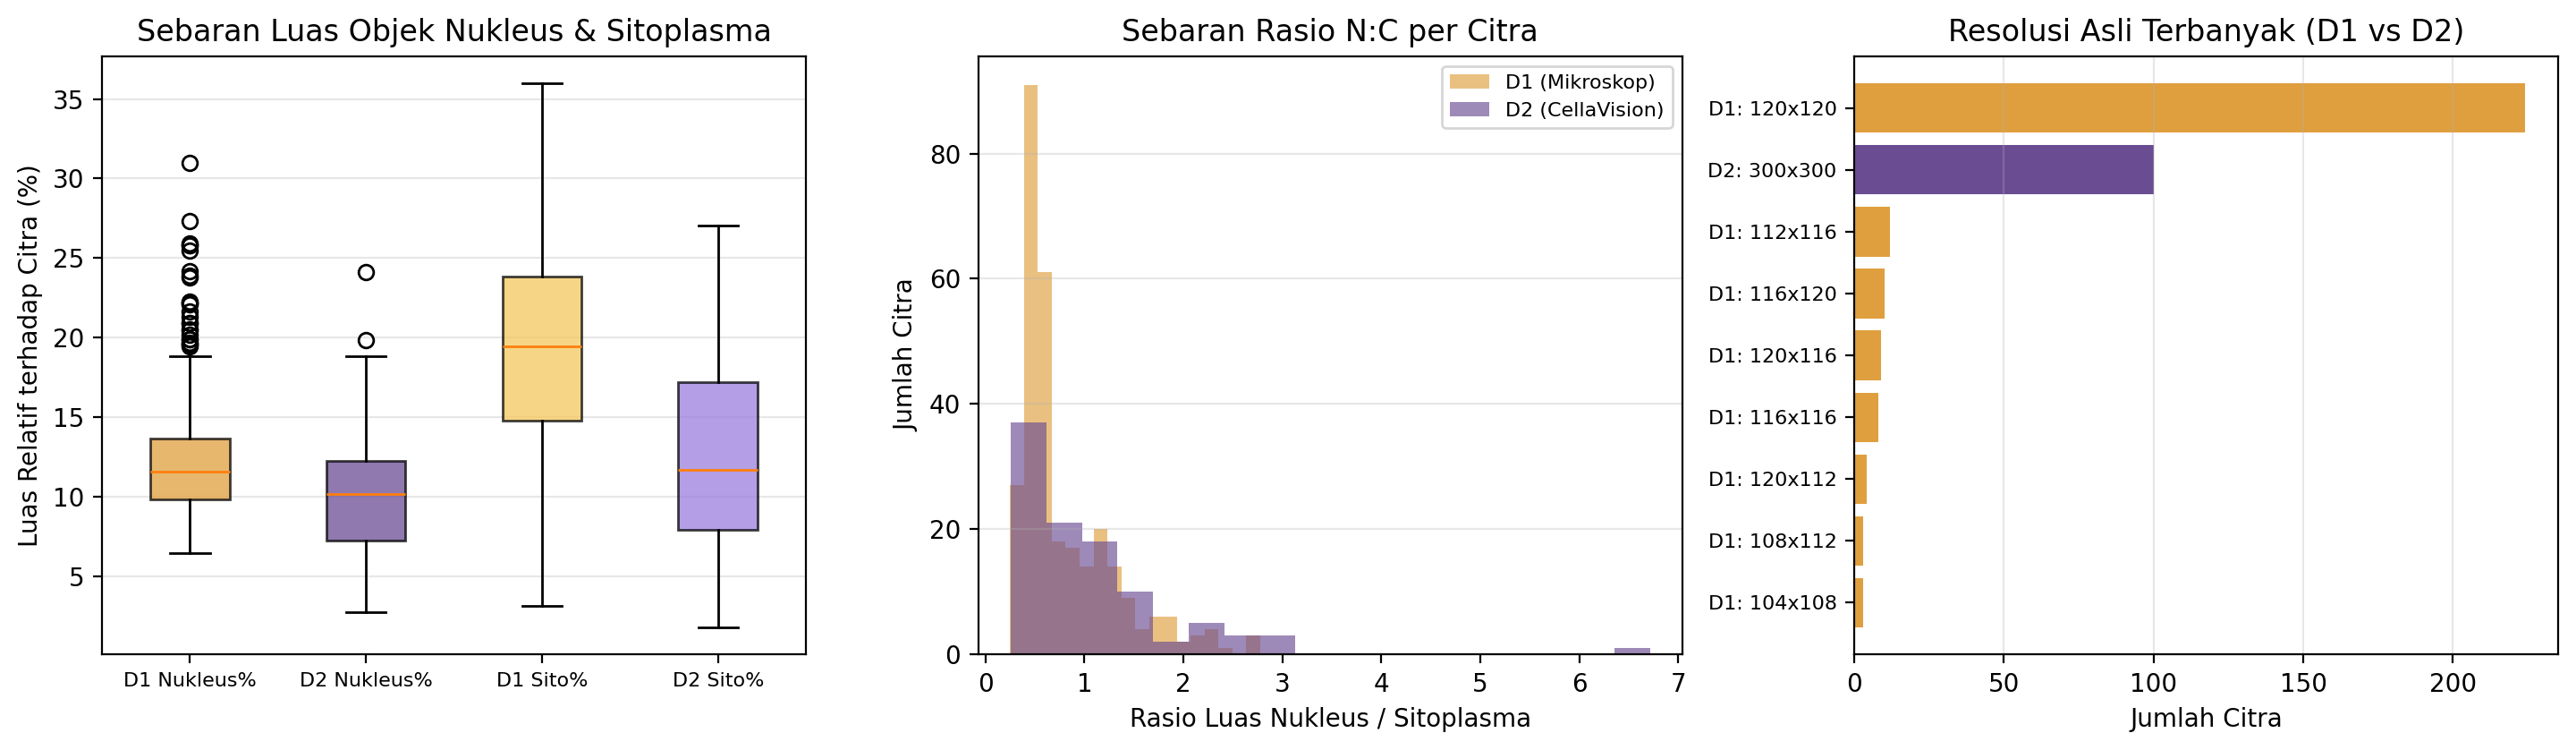

=== fig3_stain_norm_preview.png ===


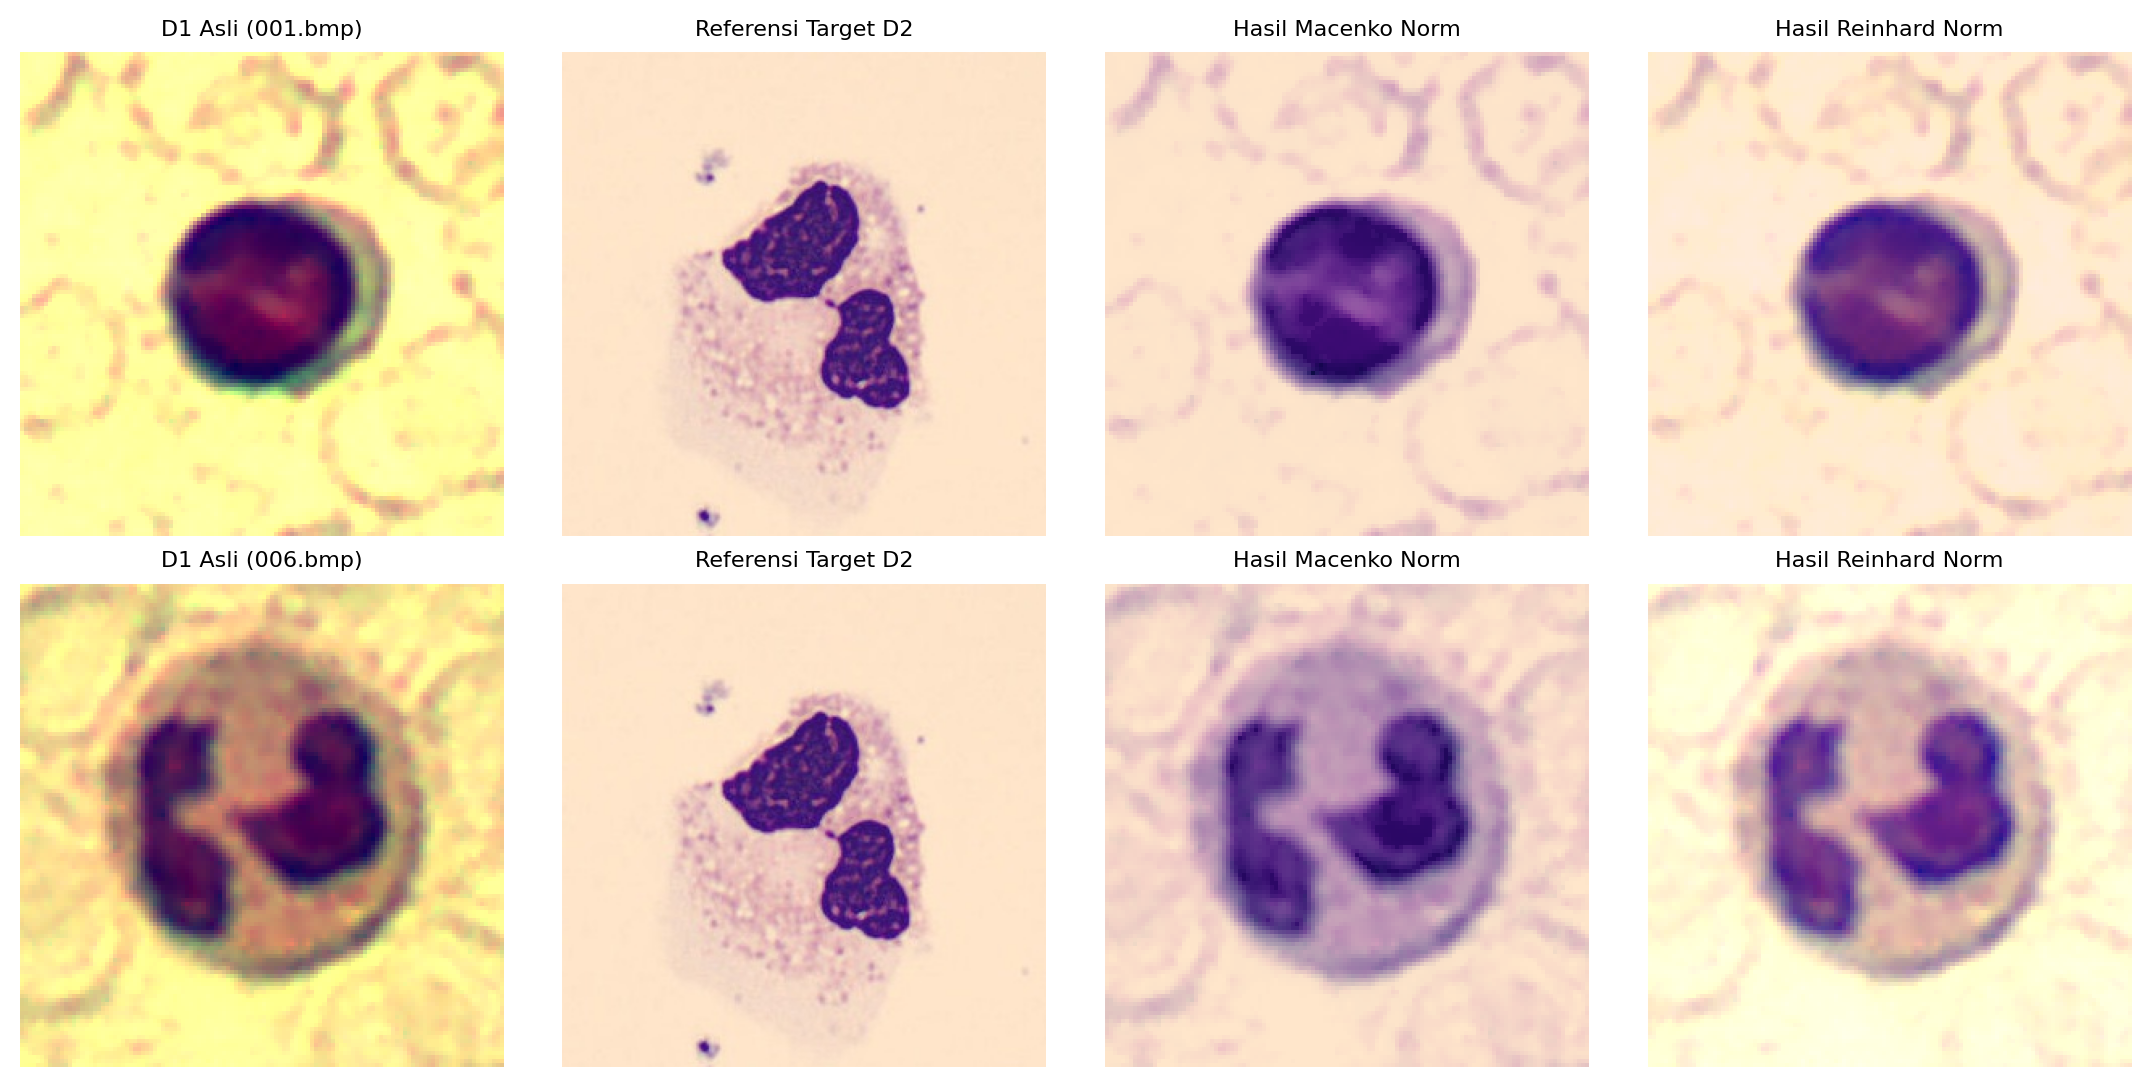

In [3]:
from IPython.display import Image, display

for fig_name in [
    "fig1_sample_overlay_d1_d2.png",
    "fig1b_mask_conversion_audit_24.png",
    "fig2_eda_distributions.png",
    "fig2b_object_size_and_nc_distributions.png",
    "fig3_stain_norm_preview.png",
]:
    print("===", fig_name, "===")
    display(Image(filename=f"docs/figures/{fig_name}"))

## 3. Latih & Evaluasi 1 Model Baseline (`U-Net ResNet-34`: Train `D1` -> Uji In-Domain `D1` & Cross-Domain `D2`)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:3561: UserWarning: nll_loss2d_forward_out_cuda_template does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:186.)
  return torch._C._nn.cross_entropy_loss(


=== RINGKASAN METRIK LENGKAP M2 BASELINE ===


,Nilai_M2_Baseline
run_name,M2_Baseline_UNet_D1_to_D2
owner,Kelompok 6 (Baseline M2)
strategy,NoAdapt
train_domain,D1
target_domain,D2
arch,unet
encoder,resnet34
freeze_encoder,False
loss,ce_dice
aug_mode,geom



=== KATEGORI KESALAHAN BASELINE M2 (D2 TEST) ===
{'Ketidakakuratan kontur tepi ringan': 7, 'Under-segmentasi sitoplasma (tepi pucat hilang)': 4, 'Over-segmentasi sitoplasma (RBC/latar ikut tersegmentasi)': 2, 'Kegagalan deteksi / pergeseran domain berat': 2}

=== PERFORMA BASELINE BERDASARKAN UKURAN SEL (D2 TEST) ===


,strategy,domain,size_bucket,n_images,fg_area_min_px,fg_area_max_px,dice_nucleus_mean,dice_cytoplasm_mean,miou_fg_mean,miou_fg_std,hd95_nucleus_mean,hd95_cytoplasm_mean
0,Baseline_M2,D2_CrossDomain,Kecil,5,5499,10249,0.8348,0.5069,0.5455,0.1481,37.41,45.38
1,Baseline_M2,D2_CrossDomain,Sedang,5,10571,15354,0.8543,0.3840,0.5193,0.2054,26.60,52.65
2,Baseline_M2,D2_CrossDomain,Besar,5,16133,25367,0.6672,0.4875,0.4879,0.3585,35.29,47.41


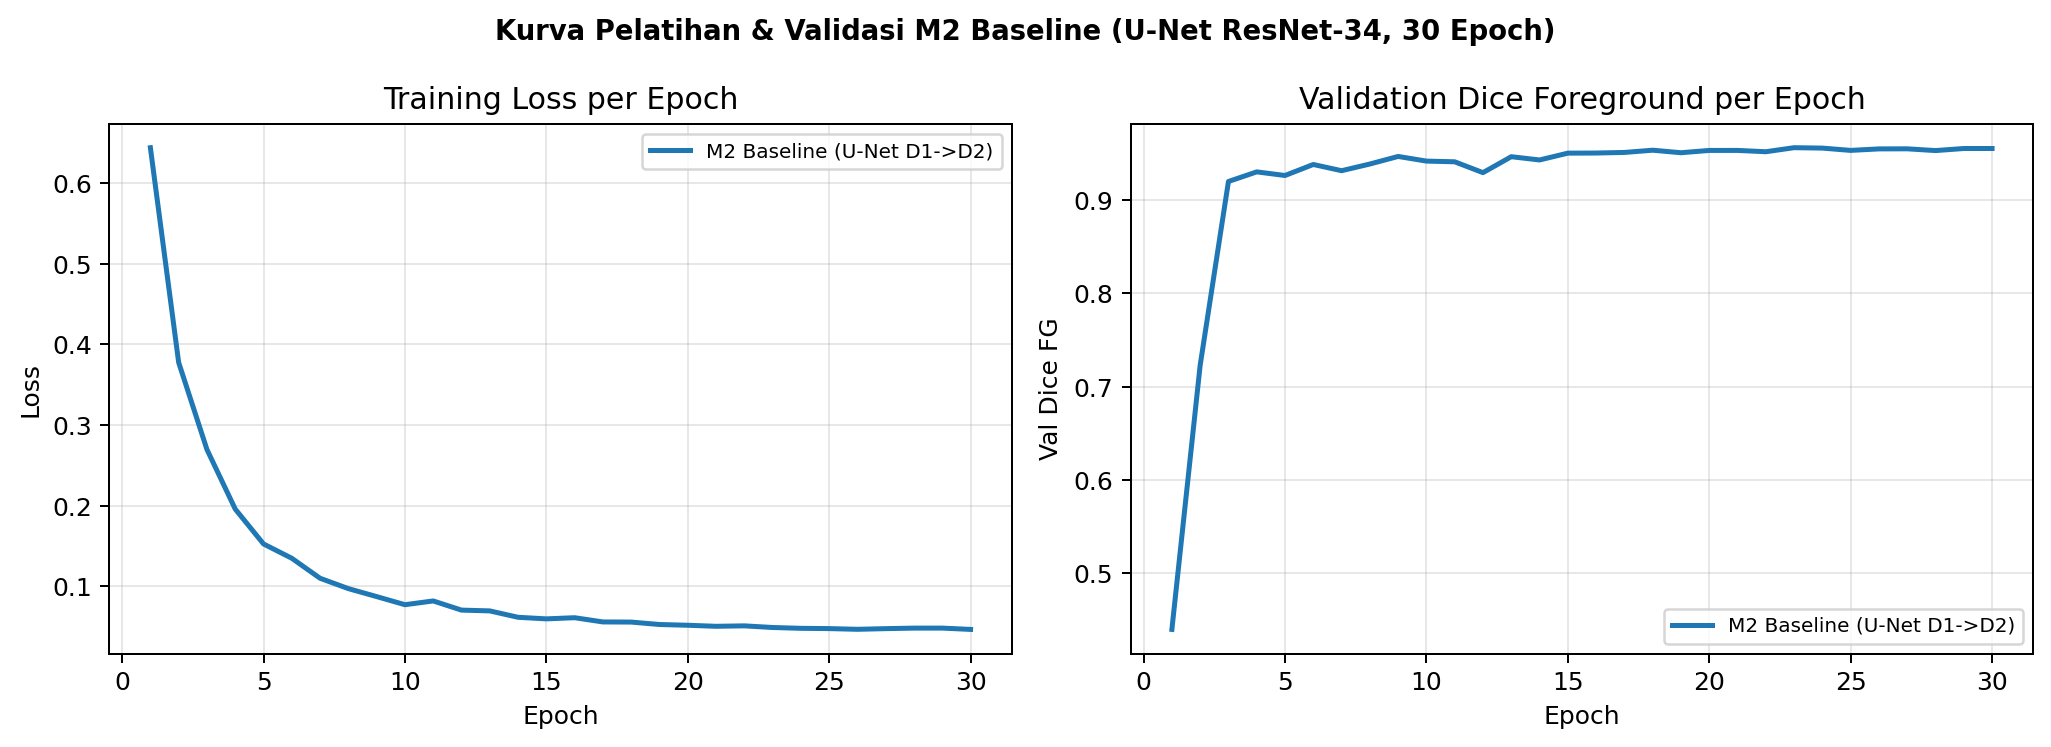

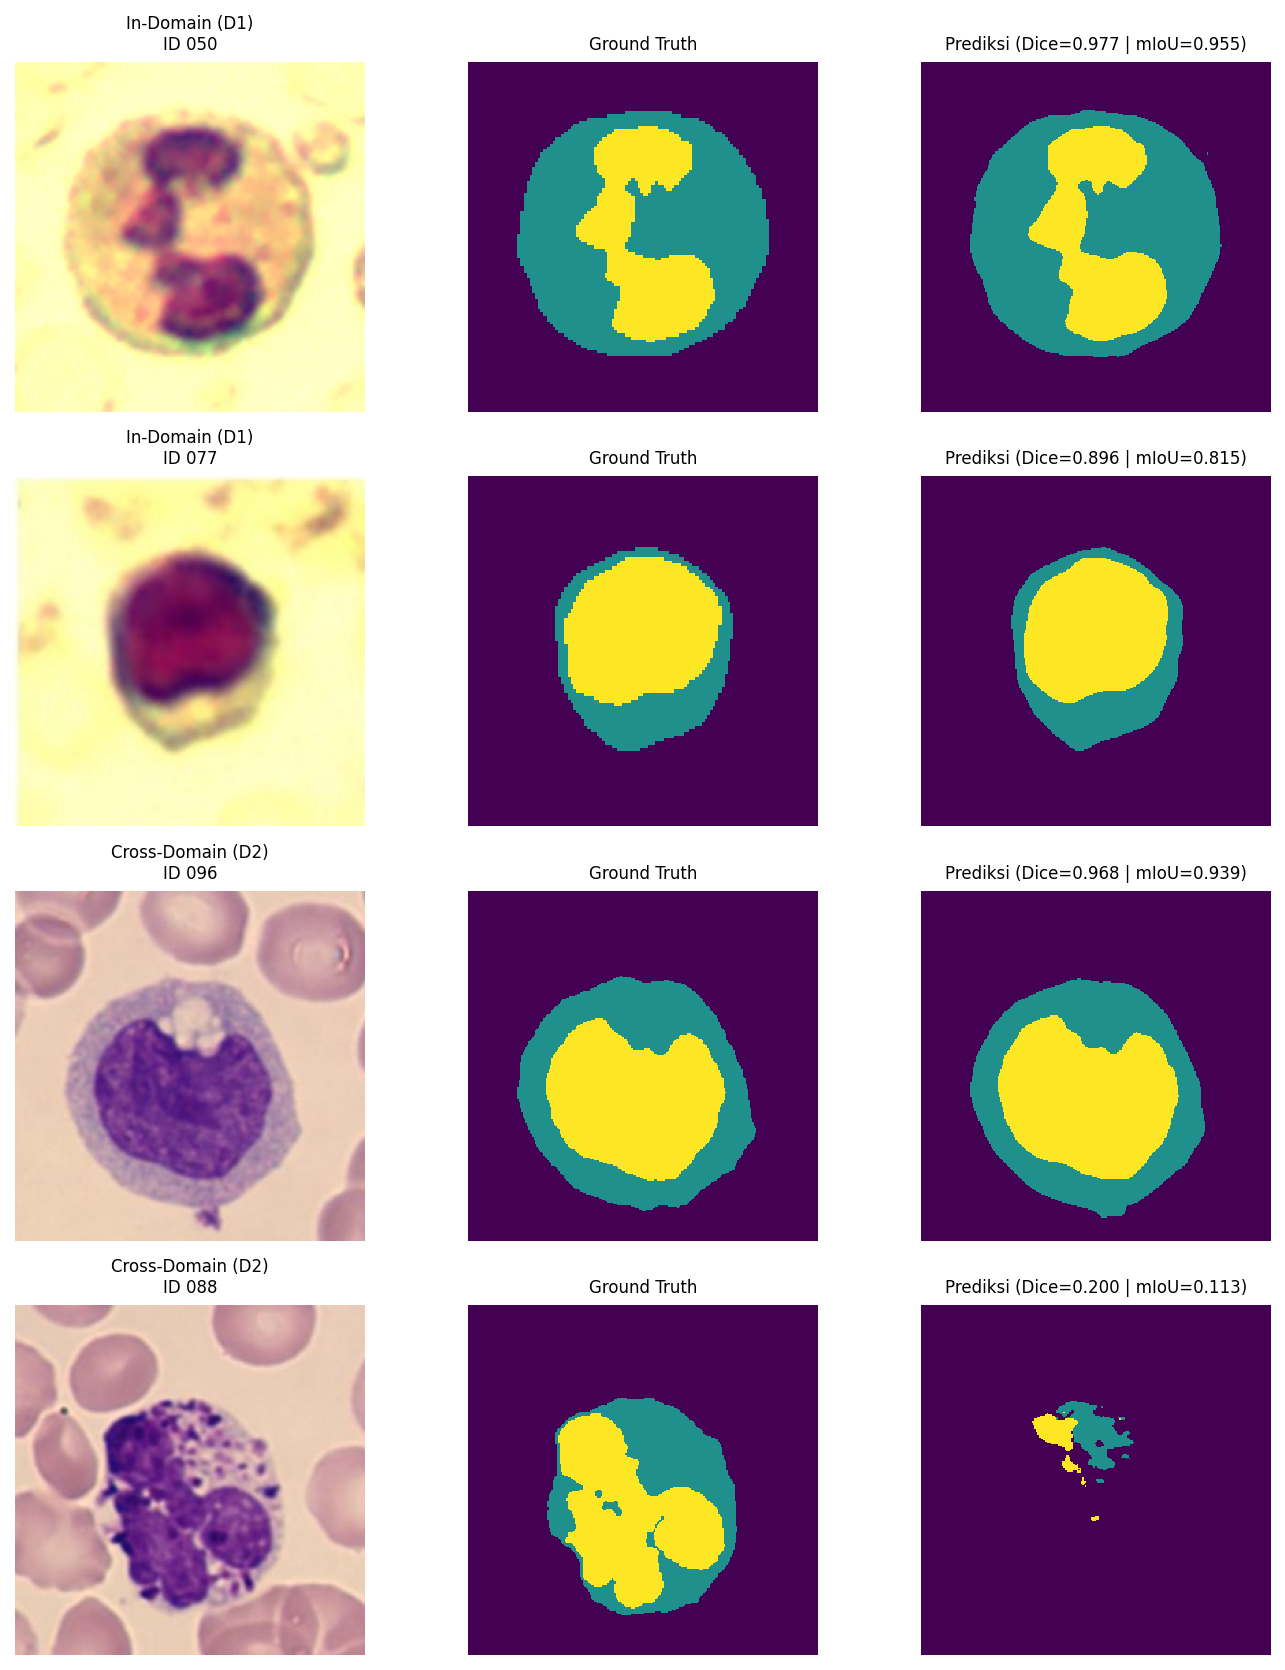

In [4]:
import os
import pandas as pd
from IPython.display import Image, display
from src.dataset import download_and_extract_zheng
from src.trainer import run_experiment
from src.xai_and_errors import (
    records_to_dataframe,
    save_baseline_preview_grid,
    save_learning_curve_plot,
    summarize_by_object_size,
    summarize_error_categories,
)

M2_LOG_PATH = "logs/m2_baseline_runs.csv"
if RUN_FROM_SCRATCH and os.path.exists(M2_LOG_PATH):
    os.remove(M2_LOG_PATH)

domain_dirs = download_and_extract_zheng("data")
split_csvs = {"D1": "splits/zheng_d1_split.csv", "D2": "splits/zheng_d2_split.csv"}

baseline_res = run_experiment(
    run_name="M2_Baseline_UNet_D1_to_D2",
    owner="Kelompok 6 (Baseline M2)",
    strategy="NoAdapt",
    domain_dirs=domain_dirs,
    split_csvs=split_csvs,
    train_domain="D1",
    target_domain="D2",
    arch="unet",
    encoder_name="resnet34",
    loss_name="ce_dice",
    aug_mode="geom",
    seed=42,
    epochs=30,
    log_csv_path=M2_LOG_PATH,
    save_weights_path="weights/M2_Baseline_UNet_D1_to_D2.pth",
    capture_test_records=True,
    history_dir="logs/histories",
)

df_m2 = pd.read_csv(M2_LOG_PATH)
df_m2["delta_miou_drop"] = (df_m2["in_miou_fg"] - df_m2["cross_miou_fg"]).round(4)
print("=== RINGKASAN METRIK LENGKAP M2 BASELINE ===")
display(df_m2.T.rename(columns={0: "Nilai_M2_Baseline"}))

df_in_rec = records_to_dataframe(baseline_res["in_records"], strategy="Baseline_M2", domain_label="D1_InDomain")
df_cr_rec = records_to_dataframe(baseline_res["cross_records"], strategy="Baseline_M2", domain_label="D2_CrossDomain")
df_per_img = pd.concat([df_in_rec, df_cr_rec], ignore_index=True)
df_per_img.to_csv("logs/m2_baseline_per_image.csv", index=False)

print("\n=== KATEGORI KESALAHAN BASELINE M2 (D2 TEST) ===")
print(summarize_error_categories(baseline_res["cross_records"]))

print("\n=== PERFORMA BASELINE BERDASARKAN UKURAN SEL (D2 TEST) ===")
size_df_m2 = summarize_by_object_size(baseline_res["cross_records"], strategy="Baseline_M2", domain_label="D2_CrossDomain")
size_df_m2.to_csv("logs/m2_baseline_size_breakdown.csv", index=False)
display(size_df_m2)

save_learning_curve_plot(
    {"M2 Baseline (U-Net D1->D2)": "logs/histories/M2_Baseline_UNet_D1_to_D2.csv"},
    out_path="docs/figures/fig_m2_baseline_learning_curve.png",
    title="Kurva Pelatihan & Validasi M2 Baseline (U-Net ResNet-34, 30 Epoch)",
)
save_baseline_preview_grid(
    baseline_res["in_records"],
    baseline_res["cross_records"],
    out_path="docs/figures/fig_m2_baseline_predictions.png",
    n_each=2,
    first_label="In-Domain (D1)",
    second_label="Cross-Domain (D2)",
)
display(Image(filename="docs/figures/fig_m2_baseline_learning_curve.png"))
display(Image(filename="docs/figures/fig_m2_baseline_predictions.png"))

## 4. Bundel Arsip & Simpan Keseluruhan Hasil M2 ke Google Drive Target

In [5]:
import os
import zipfile
import pandas as pd
from IPython.display import display

bundle_path = "m2_results_bundle.zip"
with zipfile.ZipFile(bundle_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for folder in ("logs", "splits", "docs/figures", "configs"):
        if not os.path.exists(folder):
            continue
        for root, _, files in os.walk(folder):
            for fname in sorted(files):
                zf.write(os.path.join(root, fname))

print("Arsip M2 dibuat di:", os.path.abspath(bundle_path))
if gdrive.connected:
    uploaded = gdrive.sync_paths(["logs", "splits", "docs/figures", "weights", "configs", bundle_path])
    print(f"[OK] {uploaded} berkas M2 tersimpan ke Google Drive: https://drive.google.com/drive/folders/{GDRIVE_FOLDER_ID}")
    remote_df = pd.DataFrame(gdrive.list_remote_files())
    if not remote_df.empty:
        print(f"Total ukuran di '{gdrive.milestone_subdir}': {remote_df['size_mb'].sum():.2f} MB ({len(remote_df)} berkas)")
        display(remote_df[["drive_path", "size_mb", "file_id"]])

Arsip M2 dibuat di: /content/UAS-DL-Kelompok6-T3A-WBC-DomainShift/m2_results_bundle.zip
[OK] 18 berkas M2 tersimpan ke Google Drive: https://drive.google.com/drive/folders/101PbkgjCD-y_OaZPzRcqZzdgjoCf2ld8
Total ukuran di 'M2_Audit_EDA_Baseline': 102.86 MB (18 berkas)


,drive_path,size_mb,file_id
0,M2_Audit_EDA_Baseline/configs/experiment_config.yaml,0.002,18c0zqZDejyfDs043NdydAlvMXfPsyyZe
1,M2_Audit_EDA_Baseline/docs/figures/fig1_sample_overlay_d1_d2.png,0.751,1xYEVUo76v6Dpl9XDTq5_EEcBkgbkB4_y
2,M2_Audit_EDA_Baseline/docs/figures/fig1b_mask_conversion_audit_24.png,2.564,1LZ9HYtNcREB-2pRxfsRuXN_wgrqo27ql
3,M2_Audit_EDA_Baseline/docs/figures/fig2_eda_distributions.png,0.106,14fpyVYRg1FYHjl8ragRmfTCRwfQbu6ky
4,M2_Audit_EDA_Baseline/docs/figures/fig2b_object_size_and_nc_distributions.png,0.132,1OWlH7qMCFCGAf2R1QfLN_1FD36RzqUim
5,M2_Audit_EDA_Baseline/docs/figures/fig3_stain_norm_preview.png,0.549,17OCwZnHxN9xNFBsQVt86eSYV1WoCm-Y4
6,M2_Audit_EDA_Baseline/docs/figures/fig_m2_baseline_learning_curve.png,0.093,1sFOAQg4P_KYqwc-jR1-pOuN9oIqF21RU
7,M2_Audit_EDA_Baseline/docs/figures/fig_m2_baseline_predictions.png,0.528,1wANS8rIpTutoP-IV6LGSHho0jeGhhwhQ
8,M2_Audit_EDA_Baseline/logs/data_audit_per_image.csv,0.073,1mKPZS3YsK021iETL05931ut6y9i4IXZS
9,M2_Audit_EDA_Baseline/logs/data_audit_report.json,0.009,19KkTP4MqT7fB12SBCVqLhcfzV8pwrLDl
